In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('heart.csv')
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
df.shape

(918, 12)

In [4]:
df.drop_duplicates(inplace=True)

In [5]:
df.shape

(918, 12)

In [6]:
df['RestingBP_bins'] = pd.cut(
    df['RestingBP'],
    bins = [80,120,130,140,200,float('inf')],
    labels=['Normal','Elevated','Stage 1 Hypertension','Stage 2 Hypertension','Hypertensive Crisis']
)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   Age             918 non-null    int64   
 1   Sex             918 non-null    str     
 2   ChestPainType   918 non-null    str     
 3   RestingBP       918 non-null    int64   
 4   Cholesterol     918 non-null    int64   
 5   FastingBS       918 non-null    int64   
 6   RestingECG      918 non-null    str     
 7   MaxHR           918 non-null    int64   
 8   ExerciseAngina  918 non-null    str     
 9   Oldpeak         918 non-null    float64 
 10  ST_Slope        918 non-null    str     
 11  HeartDisease    918 non-null    int64   
 12  RestingBP_bins  916 non-null    category
dtypes: category(1), float64(1), int64(6), str(5)
memory usage: 98.8 KB


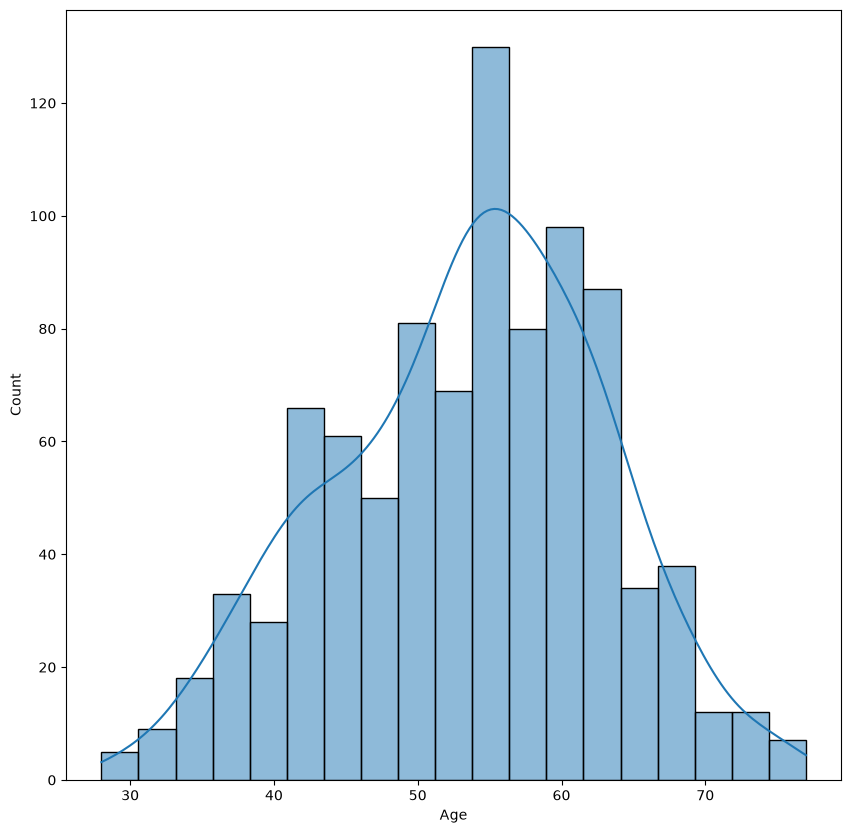

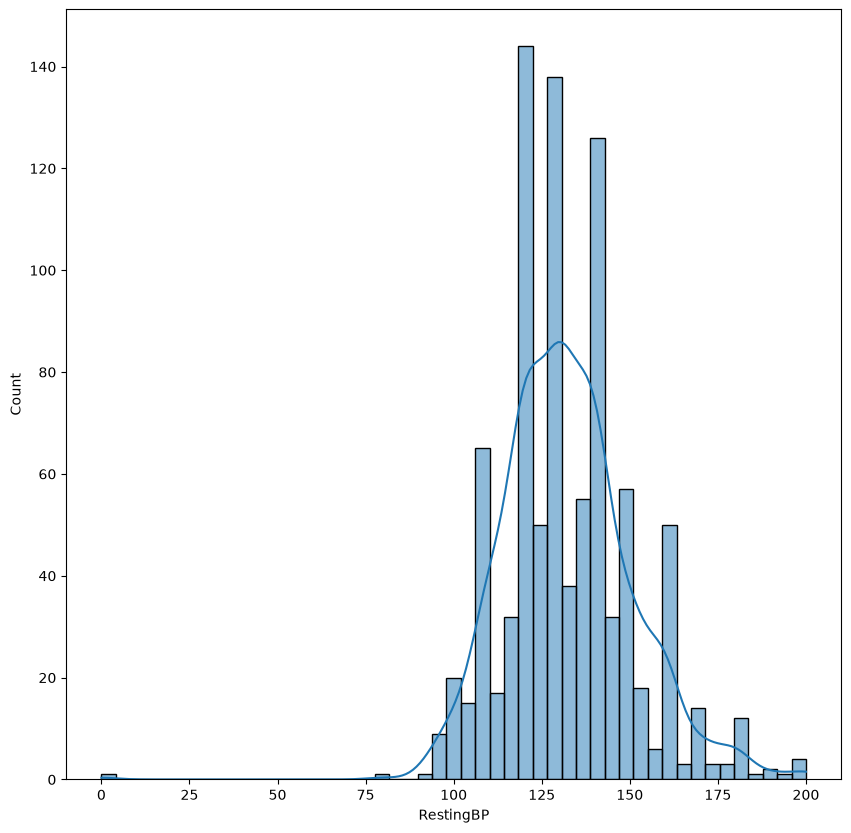

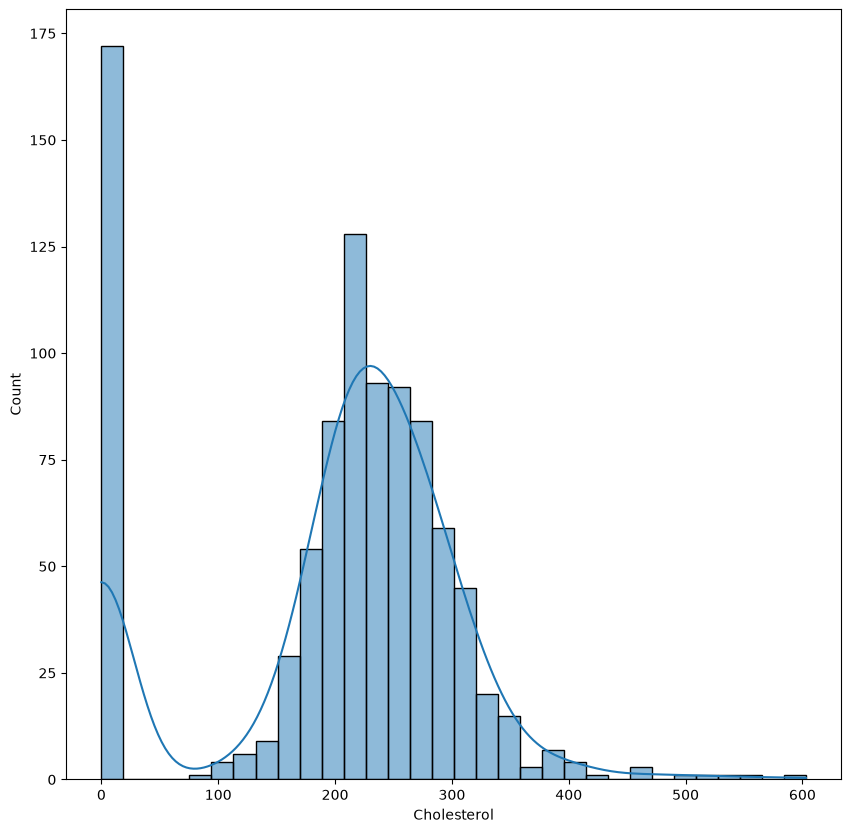

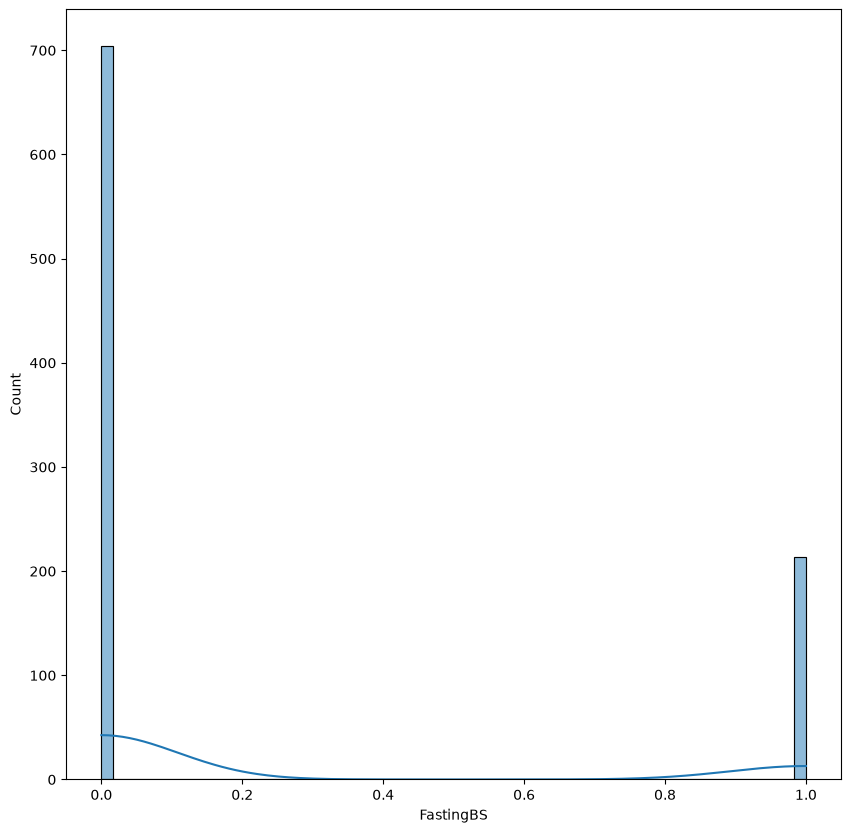

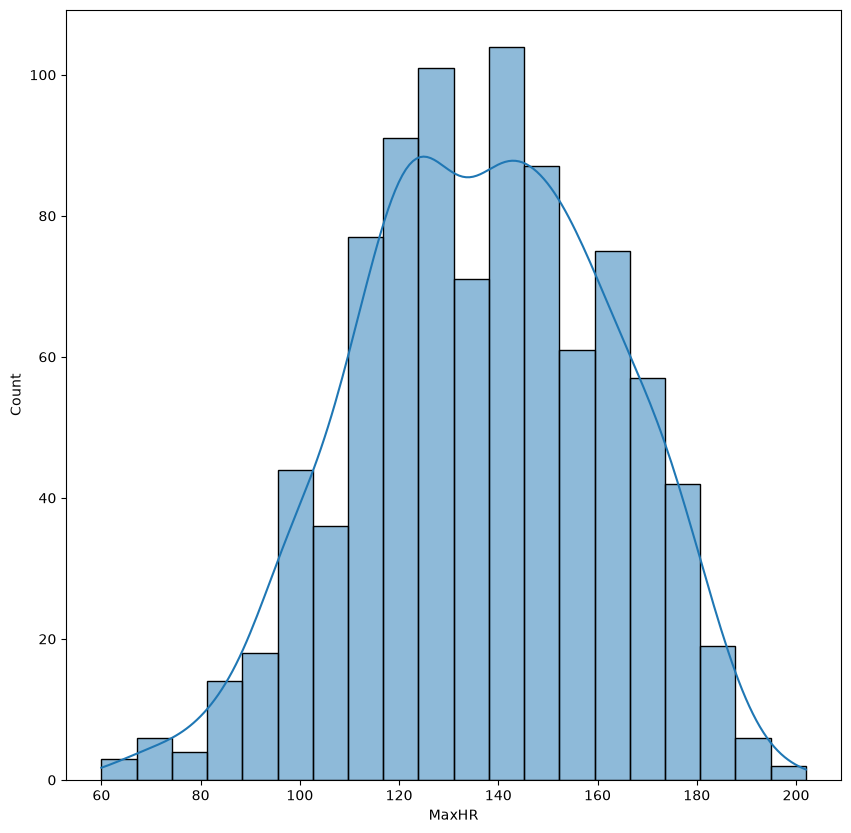

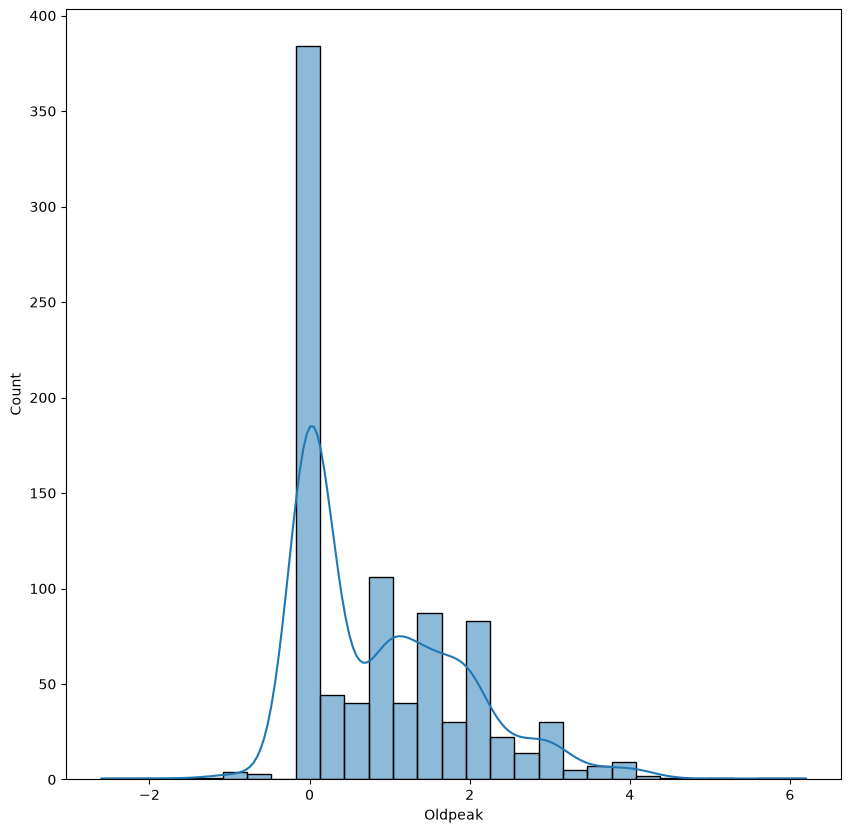

In [8]:
numaric_columns = ['Age','RestingBP','Cholesterol','FastingBS','MaxHR','Oldpeak']
for col in numaric_columns:
    plt.figure(figsize=(10,10))
    sns.histplot(df[col],kde=True)

In [9]:
ch_mean = df.loc[df['Cholesterol'] != 0 ,'Cholesterol'].mean()
re_mean = df.loc[df['RestingBP'] != 0,'RestingBP'].mean()

df['Cholesterol'] = df['Cholesterol'].replace(0,ch_mean)
df['RestingBP'] = df['RestingBP'].replace(0,re_mean)


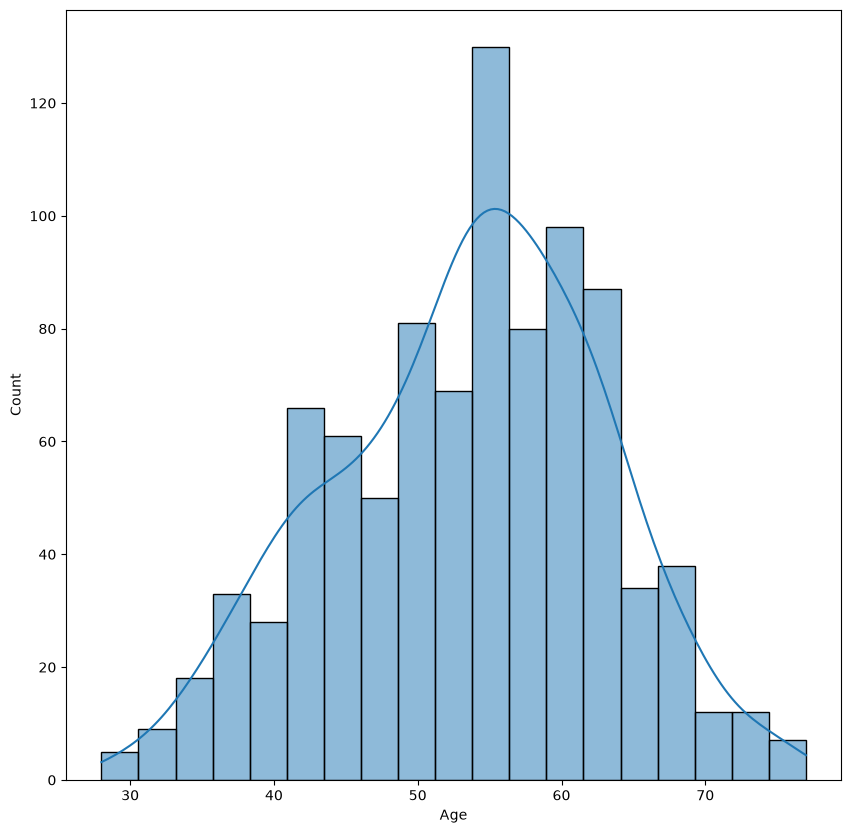

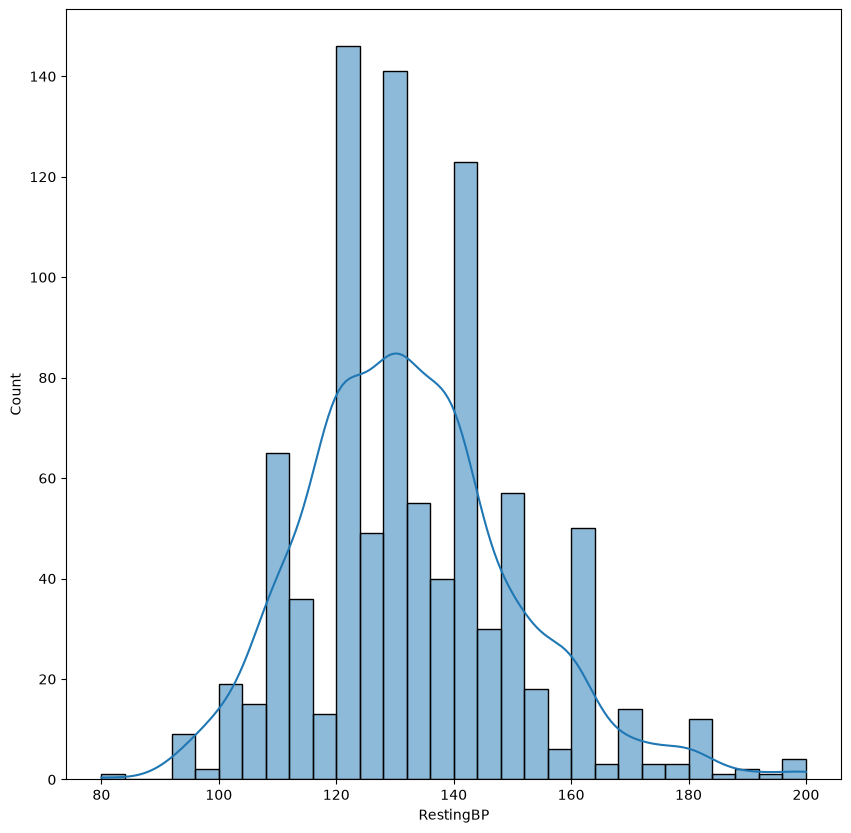

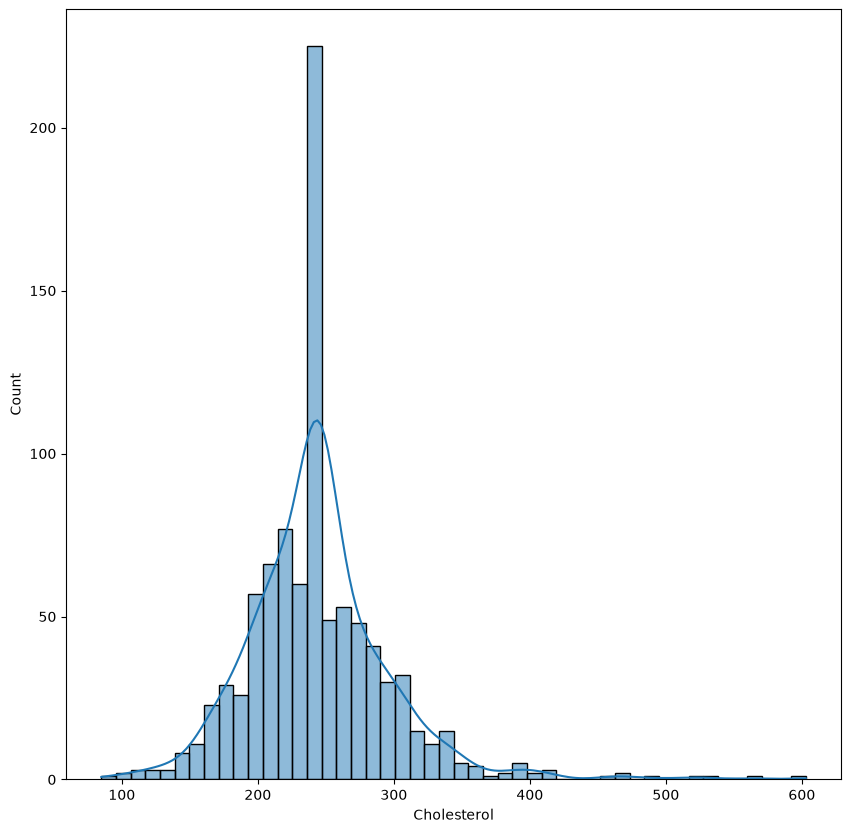

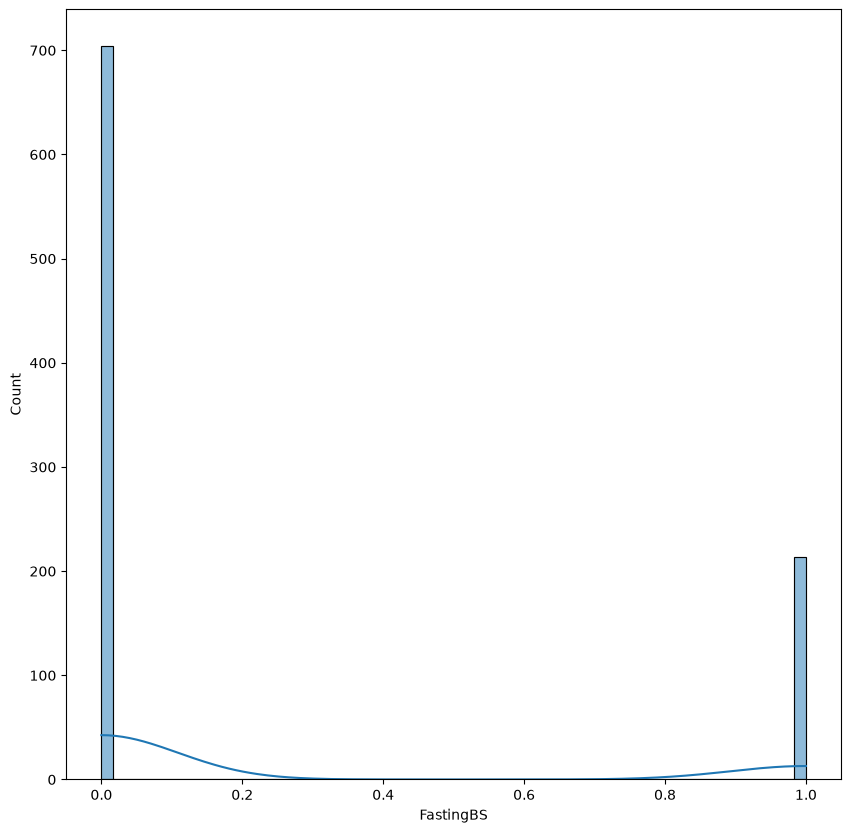

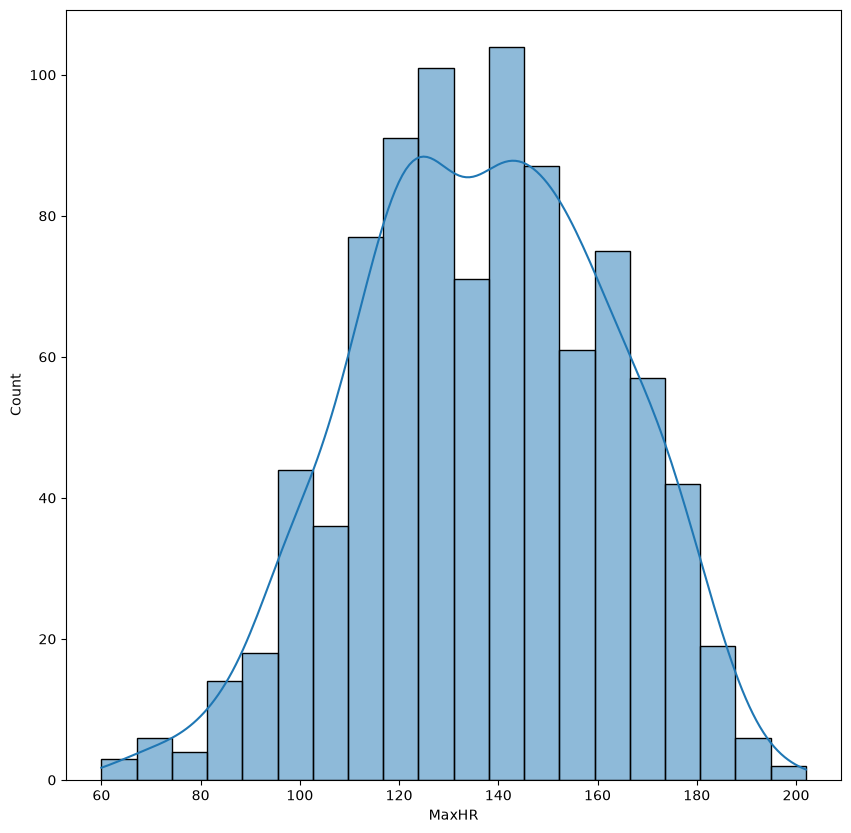

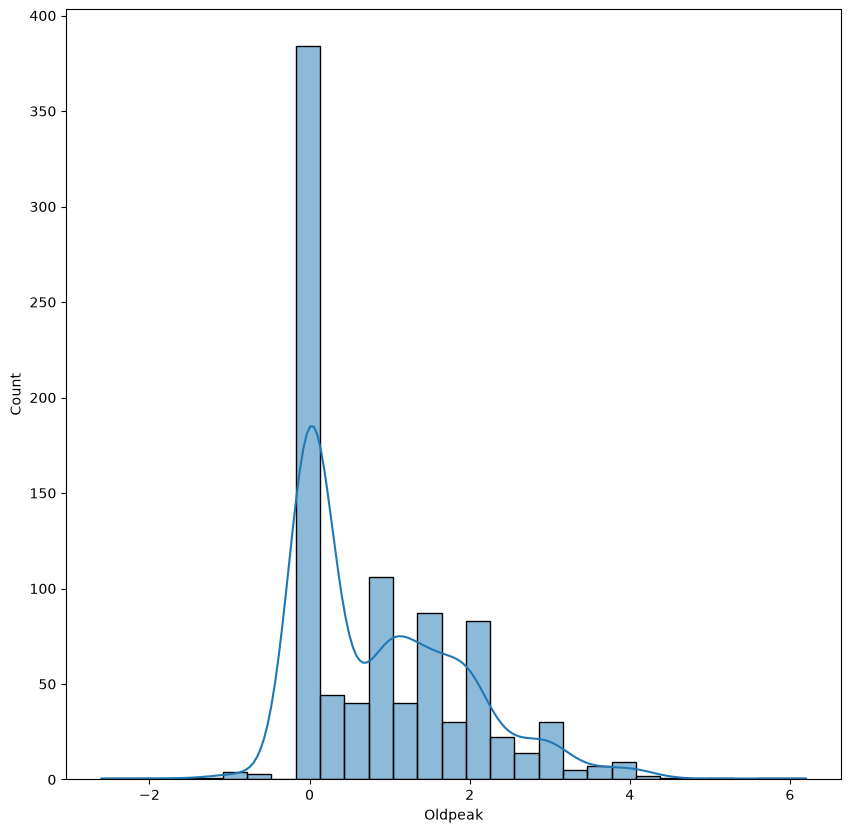

In [10]:
numaric_columns = ['Age','RestingBP','Cholesterol','FastingBS','MaxHR','Oldpeak']
for col in numaric_columns:
    plt.figure(figsize=(10,10))
    sns.histplot(df[col],kde=True)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   Age             918 non-null    int64   
 1   Sex             918 non-null    str     
 2   ChestPainType   918 non-null    str     
 3   RestingBP       918 non-null    float64 
 4   Cholesterol     918 non-null    float64 
 5   FastingBS       918 non-null    int64   
 6   RestingECG      918 non-null    str     
 7   MaxHR           918 non-null    int64   
 8   ExerciseAngina  918 non-null    str     
 9   Oldpeak         918 non-null    float64 
 10  ST_Slope        918 non-null    str     
 11  HeartDisease    918 non-null    int64   
 12  RestingBP_bins  916 non-null    category
dtypes: category(1), float64(3), int64(4), str(5)
memory usage: 98.8 KB


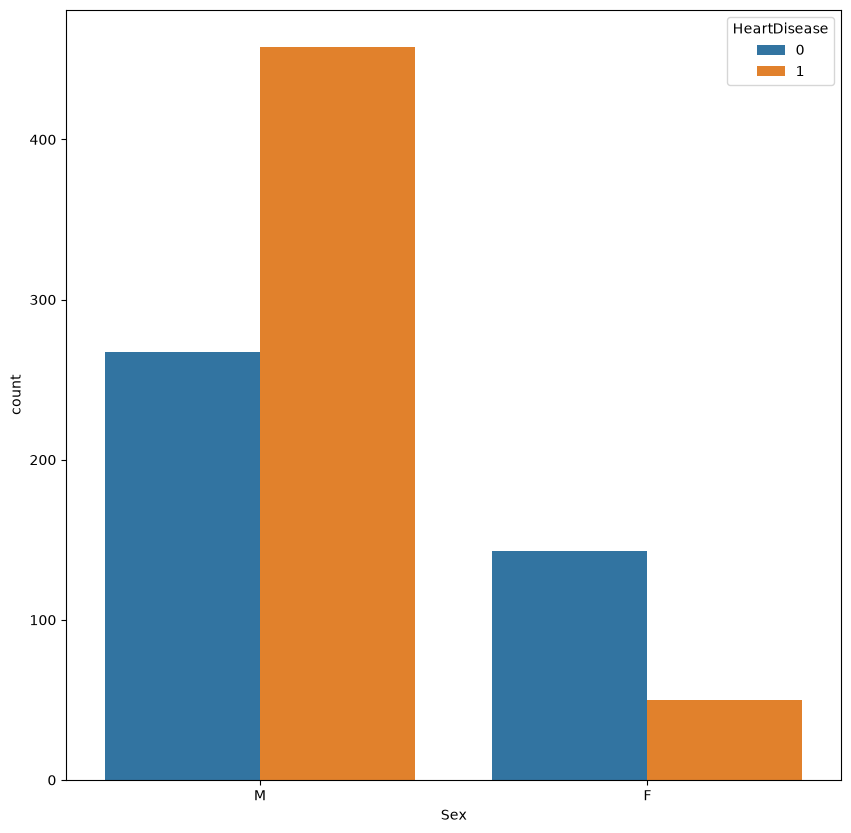

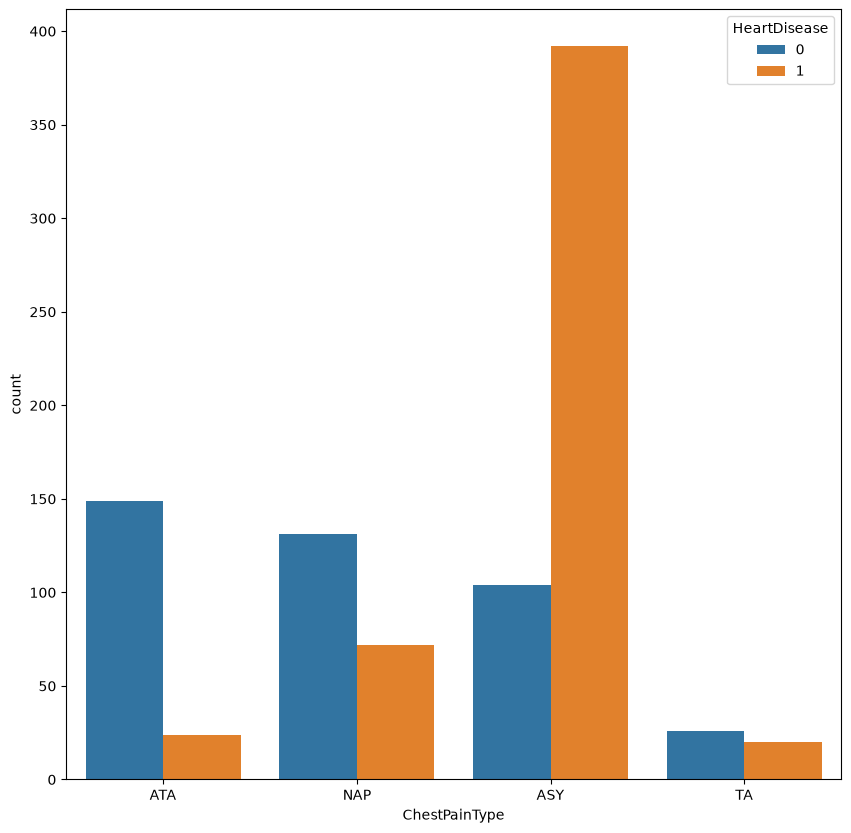

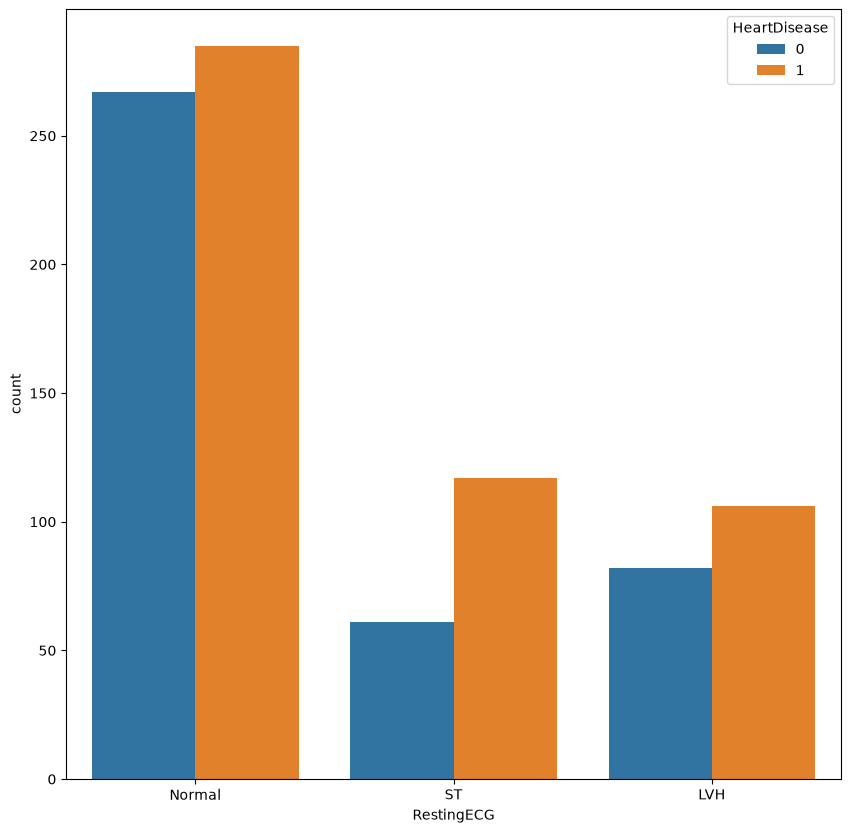

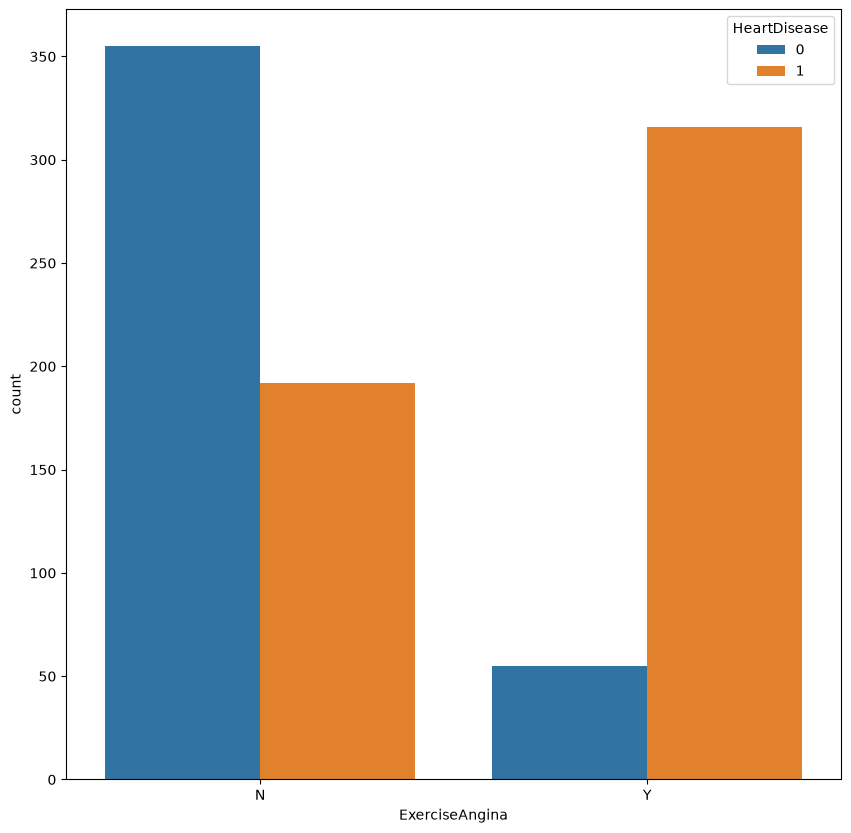

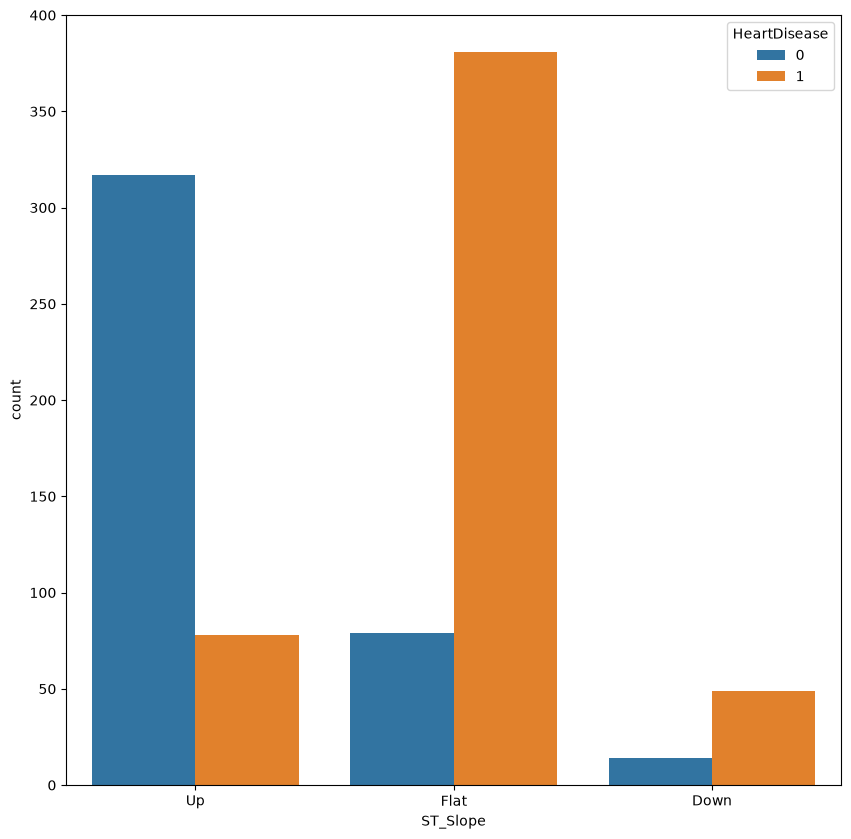

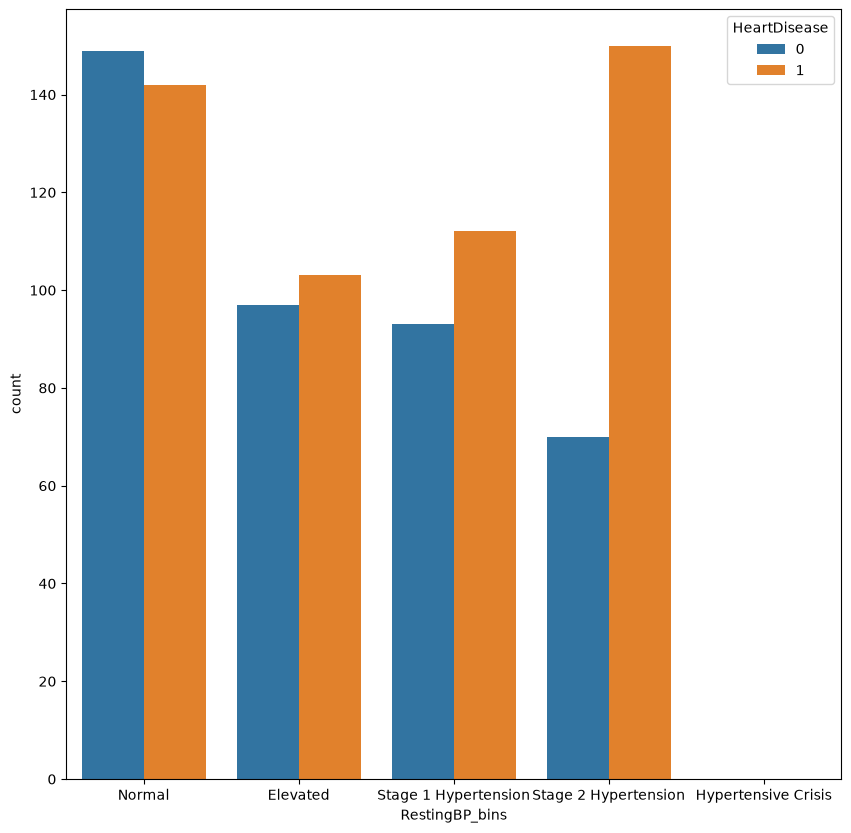

In [12]:
categorical_data = ['Sex','ChestPainType','RestingECG','ExerciseAngina','ST_Slope','RestingBP_bins']
for col in categorical_data:
    plt.figure(figsize=(10,10))
    sns.countplot(x = df[col],hue=df['HeartDisease'])

<Axes: >

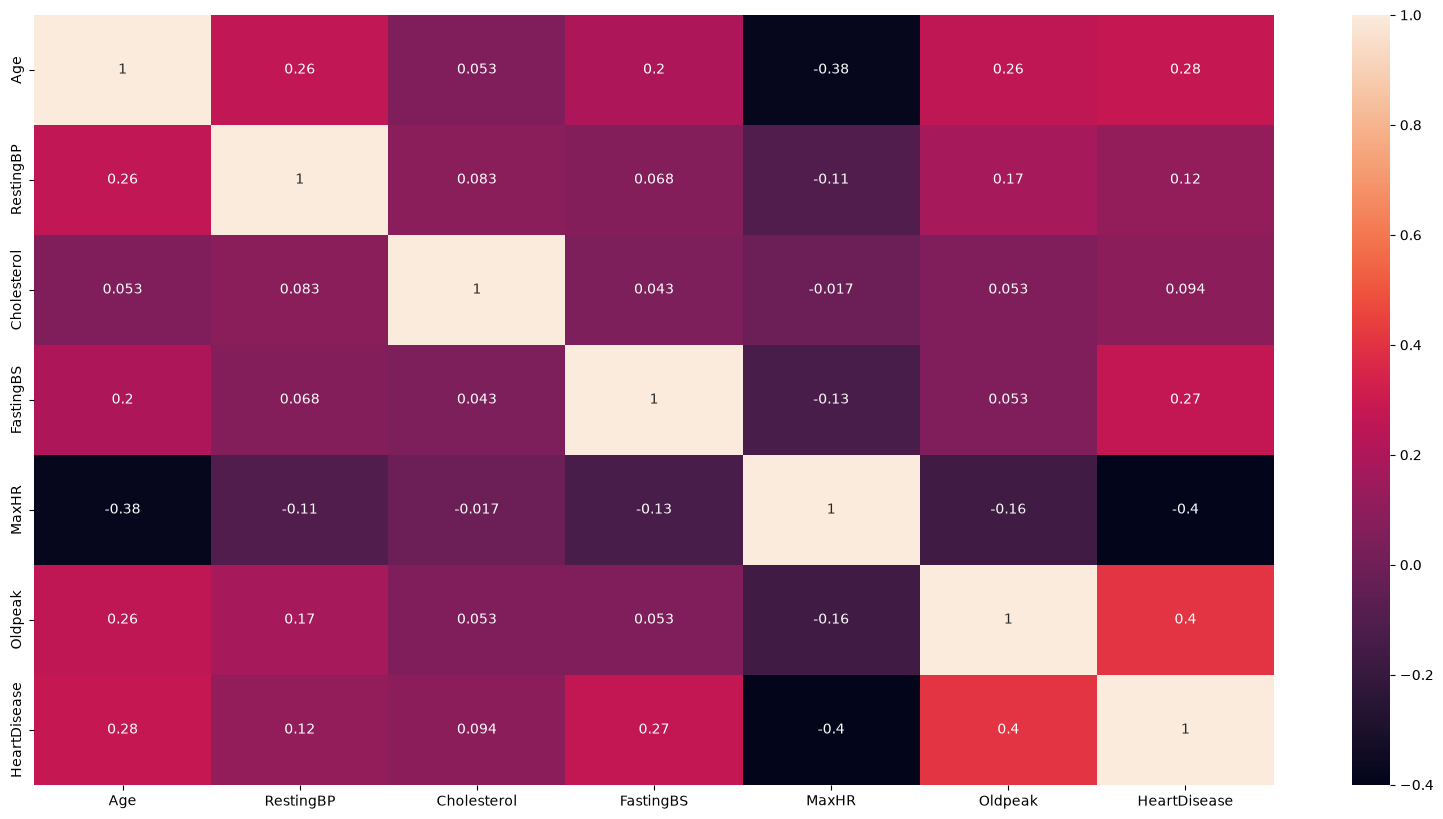

In [13]:
plt.figure(figsize=(20,10))
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [14]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,RestingBP_bins
0,40,M,ATA,140.0,289.0,0,Normal,172,N,0.0,Up,0,Stage 1 Hypertension
1,49,F,NAP,160.0,180.0,0,Normal,156,N,1.0,Flat,1,Stage 2 Hypertension
2,37,M,ATA,130.0,283.0,0,ST,98,N,0.0,Up,0,Elevated
3,48,F,ASY,138.0,214.0,0,Normal,108,Y,1.5,Flat,1,Stage 1 Hypertension
4,54,M,NAP,150.0,195.0,0,Normal,122,N,0.0,Up,0,Stage 2 Hypertension


In [15]:
df = pd.get_dummies(df,drop_first=True)

In [16]:
df = df.astype(int)

In [17]:
df.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up,RestingBP_bins_Elevated,RestingBP_bins_Stage 1 Hypertension,RestingBP_bins_Stage 2 Hypertension,RestingBP_bins_Hypertensive Crisis
0,40,140,289,0,172,0,0,1,1,0,0,1,0,0,0,1,0,1,0,0
1,49,160,180,0,156,1,1,0,0,1,0,1,0,0,1,0,0,0,1,0
2,37,130,283,0,98,0,0,1,1,0,0,0,1,0,0,1,1,0,0,0
3,48,138,214,0,108,1,1,0,0,0,0,1,0,1,1,0,0,1,0,0
4,54,150,195,0,122,0,0,1,0,1,0,1,0,0,0,1,0,0,1,0


In [18]:
df.columns

Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP',
       'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST',
       'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up',
       'RestingBP_bins_Elevated', 'RestingBP_bins_Stage 1 Hypertension',
       'RestingBP_bins_Stage 2 Hypertension',
       'RestingBP_bins_Hypertensive Crisis'],
      dtype='str')

In [19]:
total_data = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP',
       'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST',
       'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up',
       'RestingBP_bins_Elevated', 'RestingBP_bins_Stage 1 Hypertension',
       'RestingBP_bins_Stage 2 Hypertension',
       'RestingBP_bins_Hypertensive Crisis']

In [20]:
from scipy.stats import pearsonr

data = {
    feature : pearsonr(df[feature],df['HeartDisease'])[0]
    for feature in total_data
}

data_df = pd.DataFrame(list(data.items()),columns=['Feature','Pearsonal Feature'])
data_df = data_df.sort_values(by = 'Pearsonal Feature',ascending=False)
data_df

,Feature,Pearsonal Feature
6,HeartDisease,1.000000
14,ST_Slope_Flat,0.554134
13,ExerciseAngina_Y,0.494282
5,Oldpeak,0.392385
7,Sex_M,0.305445
0,Age,0.282039
3,FastingBS,0.267291
18,RestingBP_bins_Stage 2 Hypertension,0.145046
1,RestingBP,0.117909
12,RestingECG_ST,0.102527


In [21]:
selected_data = ['ST_Slope_Flat','ExerciseAngina_Y','Oldpeak','Sex_M','Age','FastingBS','RestingBP','RestingECG_ST','Cholesterol','RestingECG_Normal','ChestPainType_NAP','ST_Slope_Up','MaxHR']


In [22]:
df.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up,RestingBP_bins_Elevated,RestingBP_bins_Stage 1 Hypertension,RestingBP_bins_Stage 2 Hypertension,RestingBP_bins_Hypertensive Crisis
0,40,140,289,0,172,0,0,1,1,0,0,1,0,0,0,1,0,1,0,0
1,49,160,180,0,156,1,1,0,0,1,0,1,0,0,1,0,0,0,1,0
2,37,130,283,0,98,0,0,1,1,0,0,0,1,0,0,1,1,0,0,0
3,48,138,214,0,108,1,1,0,0,0,0,1,0,1,1,0,0,1,0,0
4,54,150,195,0,122,0,0,1,0,1,0,1,0,0,0,1,0,0,1,0


In [23]:
df.columns

Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP',
       'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST',
       'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up',
       'RestingBP_bins_Elevated', 'RestingBP_bins_Stage 1 Hypertension',
       'RestingBP_bins_Stage 2 Hypertension',
       'RestingBP_bins_Hypertensive Crisis'],
      dtype='str')

In [24]:
categorical_datas = ['RestingBP', 'Oldpeak',
       'HeartDisease', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP',
       'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST',
       'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up',
       'RestingBP_bins_Elevated', 'RestingBP_bins_Stage 1 Hypertension',
       'RestingBP_bins_Stage 2 Hypertension',
       'RestingBP_bins_Hypertensive Crisis']

In [25]:
from scipy.stats import chi2_contingency

chi2_result = {}

for col in categorical_datas:
    contingency = pd.crosstab(df[col],df['HeartDisease'])
    chi2_stats,p_val,x,y = chi2_contingency(contingency)
    decision = 'Keep Feature' if p_val < 0.05 else "Drop Feature"
    chi2_result[col] = {
        'chi2_statistics' : chi2_stats,
        'p_value' : p_val,
        'Decision' : decision
    }

data_df = pd.DataFrame(chi2_result).T
data_df = data_df.sort_values(by = 'p_value',ascending=False)
data_df

,chi2_statistics,p_value,Decision
RestingBP_bins_Hypertensive Crisis,0.0,1.0,Drop Feature
RestingBP_bins_Stage 1 Hypertension,0.022562,0.880601,Drop Feature
RestingBP_bins_Elevated,1.331729,0.248498,Drop Feature
ChestPainType_TA,2.273802,0.131577,Drop Feature
RestingBP,92.318868,0.01459,Keep Feature
RestingECG_Normal,7.327532,0.006791,Keep Feature
RestingECG_ST,9.135266,0.002507,Keep Feature
RestingBP_bins_Stage 2 Hypertension,18.635882,0.000016,Keep Feature
ChestPainType_NAP,40.608711,0.0,Keep Feature
Sex_M,84.145101,0.0,Keep Feature


In [26]:
final_data = df[['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP',
       'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST',
       'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up',
       ]]

In [27]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [28]:
from sklearn.model_selection import train_test_split

x = final_data.drop('HeartDisease',axis=1)
y = final_data['HeartDisease']
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)
x_train = scaler.fit_transform(x_train)
x_test = scaler.fit_transform(x_test)

In [29]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(x_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [30]:
y_pred = model.predict(x_test)
from sklearn.metrics import accuracy_score

acc = accuracy_score(y_test,y_pred)
acc

0.8695652173913043

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,f1_score
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

In [32]:
from sklearn.model_selection import GridSearchCV

classifier = GridSearchCV((KNeighborsClassifier()),{
    'n_neighbors' : [1,3,5,7,9,11,13],
    'weights' : ['uniform','distance'],
    'algorithm' : ['auto','ball_tree','kd_tree','brute']
},cv=7,return_train_score=False)

In [33]:
classifier1 = GridSearchCV((DecisionTreeClassifier()),
                           {
                               'criterion' : ['gini','entropy','log_loss'],
                               'splitter' : ['best','random'],
                               'min_samples_split' : [1,2,3,4]
                           },cv=5,return_train_score=False)

In [34]:
models = {
    'Logistic' : LogisticRegression(),
    'NB' : GaussianNB(),
    'Trees' : DecisionTreeClassifier(),
    'KNN' : KNeighborsClassifier(),
    'SVM' : SVC(),
    'GridsearchCV' : classifier,
    'GridSearchCV1' : classifier1
}

In [35]:
data = []
for model,predict in models.items():
    predict.fit(x_train,y_train)
    y_pred = predict.predict(x_test)
    acc = accuracy_score(y_test,y_pred)
    f1 = f1_score(y_test,y_pred)
    data.append({
        'Model Name' : model,
        'Accuracy' : acc,
        'f1_score' : f1
    })

In [36]:
for i in data:
    print(i)

{'Model Name': 'Logistic', 'Accuracy': 0.8695652173913043, 'f1_score': 0.8857142857142857}
{'Model Name': 'NB', 'Accuracy': 0.8532608695652174, 'f1_score': 0.8682926829268293}
{'Model Name': 'Trees', 'Accuracy': 0.7663043478260869, 'f1_score': 0.7902439024390244}
{'Model Name': 'KNN', 'Accuracy': 0.8641304347826086, 'f1_score': 0.8815165876777251}
{'Model Name': 'SVM', 'Accuracy': 0.8478260869565217, 'f1_score': 0.8679245283018868}
{'Model Name': 'GridsearchCV', 'Accuracy': 0.8695652173913043, 'f1_score': 0.8857142857142857}
{'Model Name': 'GridSearchCV1', 'Accuracy': 0.7771739130434783, 'f1_score': 0.7897435897435897}


In [37]:
from sklearn.model_selection import RandomizedSearchCV

classifier2 = RandomizedSearchCV((DecisionTreeClassifier()),
                                 {
                                     
                               'criterion' : ['gini','entropy','log_loss'],
                               'splitter' : ['best','random'],
                               'min_samples_split' : [1,2,3,4]
                                 },cv=5,n_iter=7,return_train_score=False)

In [38]:
classifier2.fit(x,y)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'criterion': ['gini', 'entropy', ...], 'min_samples_split': [1, 2, ...], 'splitter': ['best', 'random']}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",7
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refi

In [39]:
result = pd.DataFrame(classifier2.cv_results_)
result


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_splitter,param_min_samples_split,param_criterion,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.003497,0.000810,0.001160,0.000226,best,2,log_loss,"{'splitter': 'best', 'min_samples_split': 2, '...",0.788043,0.706522,0.711957,0.693989,0.672131,0.714528,0.039229,5
1,0.000789,0.000129,0.000000,0.000000,random,1,entropy,"{'splitter': 'random', 'min_samples_split': 1,...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,6
2,0.003812,0.000520,0.001547,0.000164,best,3,gini,"{'splitter': 'best', 'min_samples_split': 3, '...",0.739130,0.755435,0.760870,0.693989,0.704918,0.730868,0.026853,4
3,0.002017,0.000333,0.001151,0.000237,random,2,entropy,"{'splitter': 'random', 'min_samples_split': 2,...",0.793478,0.777174,0.798913,0.781421,0.672131,0.764623,0.046910,1
4,0.000373,0.000038,0.000000,0.000000,best,1,log_loss,"{'splitter': 'best', 'min_samples_split': 1, '...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,6
5,0.001943,0.000225,0.001055,0.000227,random,2,log_loss,"{'splitter': 'random', 'min_samples_split': 2,...",0.755435,0.750000,0.750000,0.765027,0.688525,0.741797,0.027196,3
6,0.001663,0.000115,0.000784,0.000040,random,4,gini,"{'splitter': 'random', 'min_samples_split': 4,...",0.722826,0.771739,0.809783,0.770492,0.677596,0.750487,0.045708,2


In [40]:
from sklearn.ensemble import StackingClassifier

In [41]:
base_learners = [
    ('dt',DecisionTreeClassifier(random_state=42)),
    ('svm',SVC(probability=True,kernel='rbf',random_state=42)),
    ('knn',KNeighborsClassifier(n_neighbors=5)),
    ('lr',LogisticRegression(max_iter=1000)),
    ('nb',GaussianNB()),
    ('cl1',classifier),
    ('cl2',classifier1),
    ('cl3',classifier2)
]

In [42]:
meta_learners = LogisticRegression(max_iter=1000)

In [43]:
staking_clf = StackingClassifier(
    estimators = base_learners,
    final_estimator=meta_learners,
    cv = 5
)

In [44]:
staking_clf.fit(x_train,y_train)

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('dt', ...), ('svm', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",LogisticRegre...max_iter=1000)
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",5
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'auto'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",None
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,) or list of ndarray if `y` is of type `""multilabel-indicator""`.Class labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[DecisionTreeC...ndom_state=42), SVC(probabili...ndom_state=42), KNeighborsClassifier(), LogisticRegre...max_iter=1000), ...]"
final_estimator_ final_estimator_: estimatorThe classifier fit on the output of `estimators_` and responsible forfinal predictions.,LogisticRegression,LogisticRegre...max_iter=1

In [45]:
y_pred = staking_clf.predict(x_test)
acc = accuracy_score(y_test,y_pred)
acc

0.8532608695652174

In [46]:
from sklearn.ensemble import RandomForestClassifier

In [47]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    random_state=42
)

In [48]:
rf_model.fit(x_train,y_train)
rf_model

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [49]:
y_predrf = rf_model.predict(x_test)
acc = accuracy_score(y_test,y_predrf)
acc

0.8532608695652174

In [50]:
from sklearn.ensemble import AdaBoostClassifier,GradientBoostingClassifier
from xgboost import XGBClassifier

In [51]:
ada_model = AdaBoostClassifier(
    n_estimators=100,
    random_state=42
)
ada_model.fit(x_train,y_train)

,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",100
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](100,)","[0.18,0.3 ,0.35,...,0.5 ,0.49,0.49]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](100,)","[1.5 ,0.83,0.61,...,0.02,0.03,0.03]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...te=1608637542), DecisionTreeC...te=1273642419), DecisionTreeC...te=1935803228), DecisionTreeC...ate=787846414), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](15,)","[0.12,0.02,0.22,...,0.07,0.01,0.14]"


In [52]:
y_pred_ada = ada_model.predict(x_test)

acc = accuracy_score(y_test,y_pred_ada)
acc

0.8532608695652174

In [53]:
gd_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

In [54]:
gd_model.fit(x_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [55]:
y_pred = gd_model.predict(x_test)
acc = accuracy_score(y_test,y_pred)
acc

0.8586956521739131

In [56]:
xgb_model = XGBClassifier(
    n_estimators = 100,
    learning_rate = 0.1,
    max_depth = 3,
    use_label_encoder = False,
    eval_metric = 'mlogloss',
    random_state = 42
)

In [57]:
xgb_model.fit(x_train,y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'mlogloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [58]:
y_pred = xgb_model.predict(x_test)
acc = accuracy_score(y_test,y_pred)
acc

0.7282608695652174

In [59]:
import joblib as jb
jb.dump(models['Logistic'],'model_heart.pkl')
jb.dump(final_data.columns.tolist(),'model_columns.pkl')

['model_columns.pkl']

In [60]:
jb.dump(scaler,'model_heart_scaler.pkl')

['model_heart_scaler.pkl']